In [3]:
from google.colab import files
uploaded = files.upload()

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())

display(df.head())

Saving movies_success_feature_engineered.csv to movies_success_feature_engineered.csv
Dataset shape: (4998, 31)
Column names:
['color', 'director_name', 'num_critic_for_reviews', 'duration', 'director_facebook_likes', 'actor_3_facebook_likes', 'actor_2_name', 'actor_1_facebook_likes', 'gross', 'genres', 'actor_1_name', 'movie_title', 'num_voted_users', 'cast_total_facebook_likes', 'actor_3_name', 'facenumber_in_poster', 'plot_keywords', 'num_user_for_reviews', 'language', 'country', 'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes', 'aspect_ratio', 'movie_facebook_likes', 'production_company', 'release_month', 'marketing_budget', 'imdb_score', 'success']


,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,budget,title_year,actor_2_facebook_likes,aspect_ratio,movie_facebook_likes,production_company,release_month,marketing_budget,imdb_score,success
0,1.0,0.046875,0.980500,0.747303,0.000000,0.672316,0.09375,0.516766,1.000000,0.051282,...,0.778975,0.931631,0.578528,0.118374,0.815203,1.0,0.090909,0.088799,7.9,1
1,1.0,0.046875,0.835537,0.734898,0.630775,0.687897,0.18750,0.792616,0.941433,0.123932,...,0.792190,0.912054,0.720120,0.209181,0.000000,1.0,0.818182,0.774020,7.1,1
2,1.0,0.054688,0.950066,0.703195,0.000000,0.506567,0.03125,0.696057,0.913043,0.192308,...,0.780836,0.990248,0.505282,0.209181,0.889334,1.0,0.636364,0.654546,6.8,0
3,1.0,0.054688,1.000000,0.727720,0.995574,1.000000,0.12500,0.763218,0.965557,0.123932,...,0.781969,0.960961,0.849130,0.209181,0.940828,1.0,0.454545,0.438690,8.5,1
4,1.0,0.000000,0.668415,0.616740,0.486175,0.589472,0.00000,0.365227,0.778935,0.213675,...,0.640368,0.892456,0.216859,0.209181,0.000000,1.0,0.454545,0.432823,7.1,1


In [4]:
from sklearn.model_selection import train_test_split

if "success" not in df.columns:
    raise ValueError(
        "The dataset must contain a 'success' target column."
    )

y = df["success"].copy()

# Exclude target, IMDb score, and movie URL from predictors
X = df.drop(
    columns=["success", "imdb_score", "movie_imdb_link"],
    errors="ignore"
).copy()

# This cell expects the cleaned dataset to have encoded features.
# Remove any remaining non-numeric columns if they are not encoded.
X = X.select_dtypes(include=np.number)

# Remove columns with no variation
X = X.loc[:, X.nunique(dropna=False) > 1]

print("Original predictor count:", X.shape[1])
print("Target distribution:")
print(y.value_counts())

# Split before fitting preprocessing or feature selection
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Original predictor count: 29
Target distribution:
success
0    3240
1    1758
Name: count, dtype: int64
Training shape: (3998, 29)
Testing shape: (1000, 29)


In [5]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Preprocessing completed.")

Preprocessing completed.


In [6]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

k = min(10, X_train.shape[1])

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=k
)

X_train_selected = selector.fit_transform(
    X_train_scaled, y_train
)

X_test_selected = selector.transform(X_test_scaled)

selected_features = X.columns[selector.get_support()].tolist()

print("Features before selection:", X_train.shape[1])
print("Features after selection:", len(selected_features))
print("\nSelected features:")
for feature in selected_features:
    print("-", feature)

Features before selection: 29
Features after selection: 10

Selected features:
- num_critic_for_reviews
- duration
- director_facebook_likes
- actor_1_facebook_likes
- num_voted_users
- cast_total_facebook_likes
- num_user_for_reviews
- content_rating
- actor_2_facebook_likes
- movie_facebook_likes


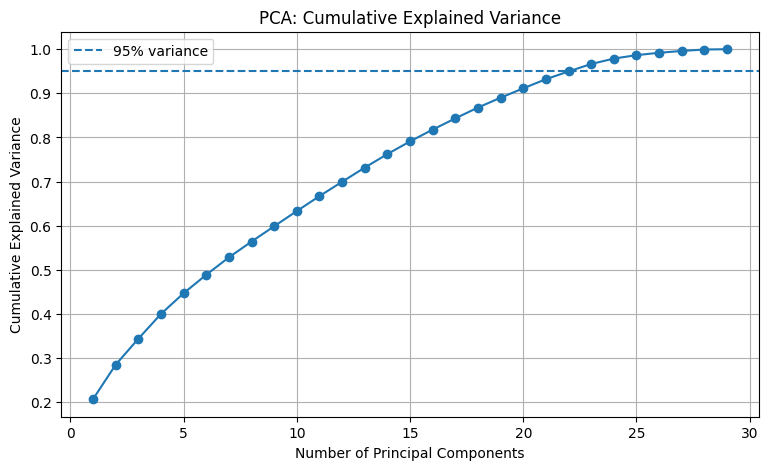

Original predictor count: 29
Components needed for 95% variance: 23


In [7]:
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X_train_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")
plt.grid(True)
plt.legend()
plt.show()

# Minimum number of components that retain at least 95% variance
n_components_95 = np.searchsorted(
    cumulative_variance, 0.95
) + 1

print("Original predictor count:", X_train.shape[1])
print("Components needed for 95% variance:", n_components_95)

In [8]:
pca = PCA(n_components=n_components_95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Training data after PCA:", X_train_pca.shape)
print("Testing data after PCA:", X_test_pca.shape)
print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Training data after PCA: (3998, 23)
Testing data after PCA: (1000, 23)
Total explained variance: 0.9665
